In [ ]:
# Hosted D2L setup: fetch the exact helper module used to build this notebook.
from pathlib import Path
from urllib.request import urlretrieve
from importlib.metadata import PackageNotFoundError, version
import importlib.util, os, subprocess, sys

required = ['numpy', 'pandas', 'matplotlib', 'requests', 'scipy', 'pillow', 'regex', 'jax', 'jaxlib', 'flax', 'optax', 'orbax-checkpoint', 'tensorflow', 'protobuf', 'ml-dtypes']
imports = {'pillow': 'PIL', 'orbax-checkpoint': 'orbax', 'protobuf': 'google.protobuf', 'ml-dtypes': 'ml_dtypes'}
pinned = {'jax': ('0.12.0.1', 'jax==0.12.0.1', 'jax[cuda12]==0.12.0.1', 'exact'), 'jaxlib': ('0.12.0.1', 'jaxlib==0.12.0.1', 'jaxlib==0.12.0.1', 'exact'), 'flax': ('0.12.12', 'flax==0.12.12', 'flax==0.12.12', 'exact'), 'optax': ('0.2.8', 'optax==0.2.8', 'optax==0.2.8', 'exact'), 'orbax-checkpoint': ('0.12.0', 'orbax-checkpoint==0.12.0', 'orbax-checkpoint==0.12.0', 'exact')}
fallbacks = {'tensorflow': 'tensorflow==2.21.0', 'protobuf': 'protobuf==7.34.1', 'ml-dtypes': 'ml-dtypes==0.5.4'}
device = os.environ.get("D2L_HOSTED_DEVICE", "auto").lower()
if device not in ("auto", "cpu", "gpu"):
    raise ValueError(f"Invalid D2L_HOSTED_DEVICE={device!r}")
if device == "auto":
    try:
        gpu = (Path("/dev/nvidia0").exists() or
               subprocess.run(["nvidia-smi", "-L"], capture_output=True,
                              timeout=5).returncode == 0)
    except (FileNotFoundError, subprocess.SubprocessError):
        gpu = False
else:
    gpu = device == "gpu"
if not gpu:
    os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")
    os.environ.setdefault("JAX_PLATFORMS", "cpu")
tensorflow_version = None
if 'jax' in ("tensorflow", "jax"):
    try:
        tensorflow_version = version("tensorflow")
    except PackageNotFoundError:
        pass
# Colab's CPU image currently carries a CUDA-enabled TensorFlow wheel. Its
# first ordinary tensor operation probes CUDA and emits an error-level cuInit
# diagnostic. JAX notebooks also use TensorFlow for data loading, so overlay
# the matching CPU build in both CPU variants. Keep the provider's
# ``tensorflow`` distribution metadata: other preinstalled Colab packages
# depend on that distribution name, while both wheels expose the same module.
if not gpu and 'jax' in ("tensorflow", "jax"):
    try:
        tensorflow_cpu_version = version("tensorflow-cpu")
    except PackageNotFoundError:
        tensorflow_cpu_version = None
    if (tensorflow_version is not None and
            tensorflow_cpu_version != tensorflow_version):
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", "--no-deps",
            f"tensorflow-cpu=={tensorflow_version}",
        ])
if "tf-keras" in fallbacks and tensorflow_version is not None:
    fallbacks["tf-keras"] = f"tf-keras=={tensorflow_version}"
missing = []
for package in required:
    if package in pinned:
        wanted, cpu_requirement, gpu_requirement, match = pinned[package]
        requirement = gpu_requirement if gpu else cpu_requirement
        try:
            installed = version(package)
        except PackageNotFoundError:
            installed = None
        actual = (installed.split("+", 1)[0]
                  if installed is not None and match == "public" else installed)
        if actual != wanted:
            missing.append(requirement)
    elif importlib.util.find_spec(imports.get(package, package)) is None:
        missing.append(fallbacks.get(package, package))
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

mismatched = []
for package, (wanted, _, _, match) in pinned.items():
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = None
    actual = (installed.split("+", 1)[0]
              if installed is not None and match == "public" else installed)
    if actual != wanted:
        mismatched.append(f"{package}={installed!r} (expected {wanted})")
if mismatched:
    raise RuntimeError("Hosted runtime setup failed: " + ", ".join(mismatched))

root = Path(".d2l-hosted") / "8a5255b0fce49fc730baae6ea6ecc601d45bb16b"
package = root / "d2l"
package.mkdir(parents=True, exist_ok=True)
base = "https://raw.githubusercontent.com/smolix/d2l-neu/8a5255b0fce49fc730baae6ea6ecc601d45bb16b/d2l"
for name in ('__init__.py', 'jax.py'):
    target = package / name
    if not target.exists():
        urlretrieve(f"{base}/{name}", target)
if str(root.resolve()) not in sys.path:
    sys.path.insert(0, str(root.resolve()))
pythonpath = os.environ.get("PYTHONPATH", "").split(os.pathsep)
if str(root.resolve()) not in pythonpath:
    os.environ["PYTHONPATH"] = os.pathsep.join(
        [str(root.resolve()), *[entry for entry in pythonpath if entry]]
    )


# Softmax Regression from Scratch

In that section we wrote linear regression ourselves, with
tensors and automatic differentiation, so that no part of training stayed
hidden. We now do the same for softmax regression. What changes when the
model predicts a class instead of a number? Softmax regression differs from
linear regression in three places. The model computes one output per class
instead of a single number, the softmax turns these outputs, the logits, into
probabilities, and the loss is the cross-entropy instead of the squared
error. Everything else carries over. The `Trainer` runs the same training
loop, the default optimizer of `Module` performs the same minibatch SGD
update, the `FashionMNIST` class of that section delivers the
images in minibatches, and the `Classifier` class of
that section reports the loss and the accuracy on validation
data. We therefore write only the three new pieces ourselves and train the
model on Fashion-MNIST.

Writing the softmax directly from its formula exposes a numerical trap. In
single precision, $\exp(o)$ overflows to infinity once $o$ exceeds about 88,
and the softmax of the logits $(1000, 0, 0)$ comes out as `NaN` instead of
$(1, 0, 0)$. We show this failure and its remedy, and keep the direct formula
in our model, whose logits stay far below that range. The next section builds
a loss that avoids the problem altogether. Once the model is trained, we look
at what it gets wrong: its accuracy on the validation images, some of its
mistakes, and the confusion matrix, which shows which garments it takes for
which.

In [ ]:
import math
import numpy as np
import jax
from jax import numpy as jnp
from flax import nnx
import optax
from d2l import jax as d2l

## The Softmax

### Normalizing Each Row

We start with the softmax, the piece that turns the logits of the model into
probabilities. For a minibatch of $n$ examples the logits form a matrix
$\mathbf{O} = \mathbf{X}\mathbf{W} + \mathbf{b}$ with one row per example and
one column per class (that section). The softmax
acts on each row separately,

$$\mathrm{softmax}(\mathbf{O})_{ij} = \frac{\exp(O_{ij})}{\sum_{k=1}^q \exp(O_{ik})},$$

so entry $(i, j)$ of the result is the probability that the model assigns to
class $j$ for example $i$. Computing it takes three steps: exponentiate every
entry, sum each row, and divide each row by its sum. The row sums are a
reduction over the columns. A sum with `axis=1` collapses the columns, and
`keepdims=True` keeps the collapsed axis with length 1, so the sums form a
column of shape $(n, 1)$ that broadcasts against the $n \times q$ matrix in
the division (that section). On a small matrix:

In [2]:
X = d2l.tensor([[1.0, 2.0, 3.0], [4.0, 5.0, 6.0]])
d2l.reduce_sum(X, 0, keepdims=True), d2l.reduce_sum(X, 1, keepdims=True)

(Array([[5., 7., 9.]], dtype=float32),
 Array([[ 6.],
        [15.]], dtype=float32))

Summing over axis 0 gives a row of shape $(1, 3)$, summing over axis 1 a
column of shape $(2, 1)$. The softmax divides by the column:

In [3]:
def softmax(O):
    O_exp = d2l.exp(O)
    return O_exp / d2l.reduce_sum(O_exp, 1, keepdims=True)  # Broadcast

We check it on two rows of logits. The first holds the logits
$(1.0, 2.2, 0.3)$ that that section computed for an image scored as
cat, chicken, and dog; the second holds three equal logits.

In [4]:
O = d2l.tensor([[1.0, 2.2, 0.3], [0.0, 0.0, 0.0]])
Y_hat = softmax(O)
Y_hat, d2l.reduce_sum(Y_hat, 1)

(Array([[0.20761092, 0.68929255, 0.10309654],
        [0.33333334, 0.33333334, 0.33333334]], dtype=float32),
 Array([1., 1.], dtype=float32))

The first row reproduces the probabilities $(0.21, 0.69, 0.10)$ computed by
hand, and equal logits give every class the probability $1/3$. Both rows sum
to 1.

### Overflow

The formula fails for large logits. The largest single-precision number is
about $3.4 \times 10^{38}$, so $\exp(o)$ overflows to infinity once $o$
exceeds $\log(3.4 \times 10^{38}) \approx 88.7$. For the logits
$(1000, 0, 0)$ both the numerator of the first entry and the row sum are
infinite, and $\infty / \infty$ is `NaN`, although the correct answer is
$(1, 0, 0)$ up to rounding. The remedy uses a fact from
that section: adding the same constant to all logits of a row does
not change their softmax. Subtracting the largest logit of each row makes
every exponent at most 0, so no exponential overflows. The framework's
built-in softmax shifts the logits in the same way. We apply the direct formula, the shifted
formula, and the built-in softmax to the same row:

In [5]:
O = d2l.tensor([[1000.0, 0.0, 0.0]])
O_max = O.max(axis=1, keepdims=True)
softmax(O), softmax(O - O_max), jax.nn.softmax(O, axis=1)

(Array([[nan,  0.,  0.]], dtype=float32),
 Array([[1., 0., 0.]], dtype=float32),
 Array([[1., 0., 0.]], dtype=float32))

The direct formula returns `NaN` in the first entry; the shifted formula and
the built-in softmax return $(1, 0, 0)$. A `NaN` spreads: the loss of the
minibatch becomes `NaN`, then its gradient, and after the update the
parameters. For our model the direct formula is safe, since its inputs are
pixel values between 0 and 1 and its weights stay small, and we keep it
because it shows the three steps plainly. Shifting would not remove a second
problem, which arises in the loss: a probability can underflow to 0, and its
logarithm is $-\infty$. that section removes both problems
by computing the logarithms of the probabilities directly from the logits.

## The Model and the Loss

### The Parameters

Each $28 \times 28$ image becomes a vector of $d = 784$ pixel values, and
there are $q = 10$ classes. The model therefore has a weight matrix
$\mathbf{W} \in \mathbb{R}^{784 \times 10}$, one column per class, and a bias
vector $\mathbf{b} \in \mathbb{R}^{10}$, together 7,850 parameters. As in
that section, we draw the weights from a normal distribution
with mean 0 and standard deviation 0.01 and set the biases to 0. Such small
weights give all classes nearly equal logits, so the model starts with
predictions close to uniform, $\hat{y}_j \approx 0.1$, and a loss close to
$\log 10 \approx 2.30$.

We register $\mathbf{W}$ and $\mathbf{b}$ as parameters of the module with
the framework's parameter type, as in that section. The
default optimizer that `Classifier` inherits from `Module`, minibatch SGD at
the learning rate `lr` (that section), finds registered
parameters by itself, so this model needs no `configure_optimizers` of its
own.

`nnx.Param` marks each array as a trainable parameter, so
`nnx.state(model)` contains `W` and `b`, and the default optimizer,
`optax.sgd`, updates them. As in that section, the argument
`rngs` supplies the random key for the initialization; without it, the model
draws a new one on every run.

In [6]:
class SoftmaxRegressionScratch(d2l.Classifier):
    """Softmax regression implemented from scratch."""
    def __init__(self, num_inputs, num_outputs, lr, std=0.01, rngs=None):
        super().__init__()
        self.save_hyperparameters(ignore=['rngs'])
        rngs = nnx.Rngs(d2l.get_key()) if rngs is None else rngs
        self.W = nnx.Param(
            rngs.params.normal((num_inputs, num_outputs)) * std)
        self.b = nnx.Param(jnp.zeros(num_outputs))

### The Forward Pass

A minibatch of $n$ images arrives as a four-dimensional tensor
(that section). The method `forward` reshapes it into the
$n \times 784$ matrix $\mathbf{X}$, one flattened image per row, computes the
logits $\mathbf{O} = \mathbf{X}\mathbf{W} + \mathbf{b}$, with the bias added
to every row by broadcasting, and returns their softmax. Flattening discards
which pixels are neighbors. The model cannot use that information; the
convolutional networks of that section do.

The minibatch has shape $(n, 28, 28, 1)$, channels last.

In [7]:
@d2l.add_to_class(SoftmaxRegressionScratch)
def forward(self, X):
    X = d2l.reshape(X, (-1, self.num_inputs))  # One flattened image per row
    return softmax(d2l.matmul(X, self.W) + self.b)

### The Cross-Entropy Loss

The loss of one example is the negative logarithm of the probability that
the model assigns to its true class, $l = -\log \hat{y}_y$
(that section). For a minibatch we need, from each row of
$\hat{\mathbf{Y}}$, the entry in the column of that example's label. The
indexing of that section does this without a loop: the row
positions together with the vector of labels pick one entry per row. In code
the labels are class indices counted from 0. Here are two examples with
three classes and labels 0 and 2:

In [8]:
y = d2l.tensor([0, 2])
y_hat = d2l.tensor([[0.1, 0.3, 0.6], [0.3, 0.2, 0.5]])
y_hat[[0, 1], y]

Array([0.1, 0.5], dtype=float32)

The first example gives its true class the probability 0.1, the second
0.5. The function `cross_entropy` averages the negative logarithms of these
probabilities over the minibatch. Before taking the logarithm it raises each
probability to at least $10^{-12}$. A probability that has underflowed to 0
would give $\log 0 = -\infty$ and an infinite loss; with the floor, the loss
of such an example is at most $-\log 10^{-12} \approx 27.6$. The floor is a
stopgap. The gradient of a probability raised to the floor is zero, so an
example that the model gets badly wrong stops contributing to training. The
next section replaces the floor by a loss that never forms the probability.

In [9]:
def cross_entropy(y_hat, y):
    # Tiny clip to keep log finite when softmax outputs underflow to 0.
    p = jnp.clip(y_hat[jnp.arange(len(y_hat)), y], min=1e-12)
    return -d2l.reduce_mean(d2l.log(p))

cross_entropy(y_hat, y)

Array(1.4978662, dtype=float32)

The loss is the mean of $-\log 0.1 \approx 2.30$ and
$-\log 0.5 \approx 0.69$, about 1.50. It becomes the loss of our model:

In [10]:
@d2l.add_to_class(SoftmaxRegressionScratch)
def loss(self, y_hat, y):
    return cross_entropy(y_hat, y)

## Training and Evaluation

### The Training Run

With the parameters, the forward pass, and the loss in place, the `Trainer`
can fit the model to Fashion-MNIST. We train for 10 epochs with minibatches
of 256 images at learning rate 0.1. An epoch takes 235 steps, the last on the
96 images left over ($60{,}000 = 234 \times 256 + 96$). Fashion-MNIST has no separate validation split, so we validate on
its 10,000 test images (that section), and the `Trainer`
reports the validation loss and accuracy after every epoch. The number of
epochs, the minibatch size, and the learning rate influence the result,
although training does not learn them. Choosing them by their validation
accuracy is a form of model selection, and
that section asks what such choices do to
the trustworthiness of the score.

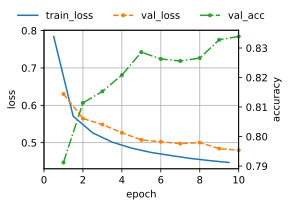

In [11]:
data = d2l.FashionMNIST(batch_size=256)
model = SoftmaxRegressionScratch(num_inputs=784, num_outputs=10, lr=0.1)
trainer = d2l.Trainer(max_epochs=10)
trainer.fit(model, data)

The training loss falls quickly during the first epoch and slowly after it.
The validation accuracy is between 75% and 80% after one epoch and about 83%
after ten. From one epoch to the next it can also drop by a point or two, since
minibatch SGD keeps moving the parameters. The training and validation
losses end close together, near 0.45 and 0.49. A model with 7,850
parameters fitted to 60,000 images can memorize little of its training
data, so it does almost as well on images it has not seen.

The method `trainer.evaluate` computes the validation metrics of a model,
means over all 10,000 validation images. After training they equal the last
point of each validation curve, which `trainer.history['val_loss'][-1]` and
`trainer.history['val_acc'][-1]` hold.

In [12]:
trainer.evaluate(model, data)

{'loss': 0.479949658203125, 'acc': 0.8339}

The model labels about 83% of the validation images correctly. Repeated
runs stay between 82% and 84%: the random
initialization and the order of the minibatches change the result by about
a point.

### Misclassified Images

The accuracy tells us how often the model errs, not on which images. We take
the first minibatch of 256 validation images, predict the class of each, and
count the mistakes.

In [13]:
X, y = next(iter(data.val_dataloader()))
preds = d2l.astype(d2l.argmax(model(X), axis=1), y.dtype)
wrong = preds != y
print(f'{int(d2l.reduce_sum(d2l.astype(wrong, d2l.int32)))} of {len(y)} wrong')

34 of 256 wrong


We show the first eight misclassified images. Each title gives the true
class above the predicted one.

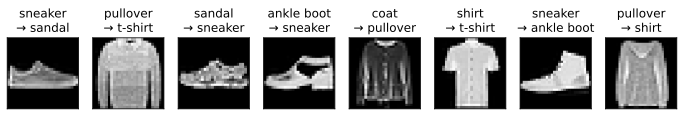

In [14]:
labels = [f'{true}\n→ {pred}' for true, pred in zip(
    data.text_labels(y[wrong]), data.text_labels(preds[wrong]))]
data.visualize([X[wrong], y[wrong]], labels=labels)

Between 30 and 45 of the 256 images are misclassified, in line with an
error rate of about 17%. Most mistakes confuse garments of similar outline:
one top for another, such as a coat for a pullover, or one shoe for another.
Some of the images are hard to label at $28 \times 28$ pixels even for a
person.

### The Confusion Matrix

A few images show which mistakes occur; the confusion matrix of
that section counts all of them. Its entry $N_{ij}$ is the
number of validation examples of class $j$ that the model predicts as class
$i$: rows are predicted classes and columns true classes. To count all pairs
at once we use one-hot vectors (that section). Let the rows of
$\mathbf{P} \in \{0, 1\}^{n \times q}$ be the one-hot encodings of the
predicted classes of a minibatch and the rows of
$\mathbf{Y} \in \{0, 1\}^{n \times q}$ those of the labels. Then

$$(\mathbf{P}^\top \mathbf{Y})_{ij} = \sum_{m=1}^n P_{mi} Y_{mj} = \sum_{m=1}^n \mathbf{1}\big(\hat{y}^{(m)} = i\big)\, \mathbf{1}\big(y^{(m)} = j\big),$$

since a term is 1 exactly when example $m$ is predicted as $i$ and labeled
$j$. One matrix product counts the pairs of a minibatch, and summing the
products over all validation minibatches gives $\mathbf{N}$. The function
`one_hot` builds the one-hot rows by comparing a column of class indices with
the row $(0, 1, \ldots, q-1)$, which broadcasting expands to an $n \times q$
matrix of comparisons.

In [15]:
def one_hot(y, q):
    """Rows of the q x q identity matrix, one per class index in y."""
    return d2l.astype(d2l.reshape(y, (-1, 1)) == d2l.arange(q, dtype=y.dtype),
                      d2l.float32)

N = d2l.zeros((10, 10))
for X, y in data.val_dataloader():
    P = one_hot(d2l.argmax(model(X), axis=1), 10)
    N += d2l.matmul(d2l.transpose(P), one_hot(y, 10))
int(d2l.reduce_sum(N))

10000

The counts add up to the 10,000 validation images. Dividing each column by
its sum gives the matrix $\mathbf{C}$ with $C_{ij} = N_{ij} / \sum_{i'}
N_{i'j}$, the fraction of the examples of class $j$ that are predicted as
class $i$. It estimates the probability that the model predicts class $i$
for an example of class $j$. Each column of $\mathbf{C}$ sums to 1, and its
diagonal holds the recall of each class. The display utility
`d2l.show_heatmaps` draws the matrix as a grid of colored cells. The classes
are numbered from 0 to 9 in the order T-shirt, trouser, pullover, dress,
coat, sandal, shirt, sneaker, bag, ankle boot.

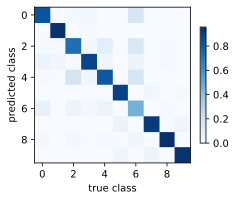

In [16]:
C = N / d2l.reduce_sum(N, 0, keepdims=True)  # Each column sums to 1
d2l.show_heatmaps(d2l.reshape(C, (1, 1, 10, 10)), xlabel='true class',
                  ylabel='predicted class', figsize=(3.5, 3.5), cmap='Blues')

The diagonal shows how often each class is recognized. Trousers, bags, and
the three kinds of shoes are recognized about 90% of the time or more, and
shirts only 40% to 70% of the time. The errors form two groups. The
four tops (T-shirts, pullovers, coats, and shirts; columns 0, 2, 4, and 6)
trade most of their errors among themselves, and nearly all of the largest
entries off the diagonal lie in this group: shirts taken for T-shirts,
pullovers, or coats, and pullovers and coats taken for each other. Sandals,
sneakers, and ankle boots (columns 5, 7, and 9) form a second, smaller
group, whose errors almost all stay among the three. The four
tops have similar outlines and differ in details such as collars, buttons,
and the length of the sleeves, which change few pixels. A shirt resembles
each of the other three in some of these details, so it collects errors
from all of them.

We have written softmax regression with tensors, trained it to about 83%
validation accuracy, and found where its errors lie: among garments of
similar shape. Two limits remain. The direct softmax and the floor in the
loss make the implementation fragile, which the next section fixes with a
loss computed from the logits. And every class score is a weighted sum of
pixels, so the boundaries between the predicted classes are hyperplanes in
the space of images. Models that first compute features from groups of
pixels, such as the multilayer perceptrons of that section,
separate the classes better.

## Summary

Softmax regression from scratch adds three components to the training code
of linear regression: a weight matrix
$\mathbf{W} \in \mathbb{R}^{784 \times 10}$ and a bias
$\mathbf{b} \in \mathbb{R}^{10}$ registered as parameters, a forward pass
that flattens the images and applies the softmax to each row of
$\mathbf{O} = \mathbf{X}\mathbf{W} + \mathbf{b}$, and the cross-entropy loss,
which picks the probability of the true class in each row by indexing. The
softmax written from its formula returns `NaN` once a logit exceeds about
88; subtracting the largest logit of each row prevents the overflow, and a
floor of $10^{-12}$ keeps the logarithm in the loss finite at the price of a
zero gradient. Ten epochs of minibatch SGD reach about 83% validation
accuracy, which `trainer.evaluate` reports. The confusion matrix, a sum of
products of one-hot matrices, shows that most errors confuse garments of
similar shape, above all shirts with T-shirts, pullovers, and coats.

## Exercises

1. [code] **Underflow.** The `softmax` of this section returns `NaN` on
   the logits $(1000, 0, 0)$, and subtracting the largest logit of the row
   fixes it.
    1. Show that `softmax` also returns `NaN` on the row
       $(-1000, -1000, -1000)$, and identify the operation that produces
       the `NaN` in this case. Check that the shifted version returns
       $(1/3, 1/3, 1/3)$.
    1. Take the logits $(0, -200, 0)$ and the label `y = 1`, the class of
       the logit $-200$. Compute the shifted softmax and `cross_entropy` of
       the result. Then compute the
       gradient of this loss with respect to the logits by automatic
       differentiation, and compare it with the gradient
       $\hat{\mathbf{y}} - \mathbf{y}$ derived in that section.
       Explain the difference, and what it means for training on an
       example that the model gets badly wrong.

1. [code] **Cross-entropy from one-hot labels.** The `cross_entropy` of this
   section selects the correct-class probability by indexing. Implement an
   alternative that follows the definition $-\sum_j y_j \log \hat{y}_j$
   literally, by converting `y` to a one-hot matrix and taking row-wise
   inner products.
    1. Use it as the `loss` of `SoftmaxRegressionScratch` and confirm that
       training is unchanged.
    1. Time both versions on random probability matrices with $256$ rows
       and $q \in \{10, 10^3, 10^5\}$ columns, and state how the memory
       that each version allocates grows with $q$.
    1. Describe a setting in which the inner-product form applies but the
       indexing form does not.

1. **Large vocabularies.** Suppose that softmax regression predicts the
   next word from a feature vector of dimension $d = 1024$. The vocabulary
   has $V = 10^6$ words, and each minibatch holds $n = 256$ examples.
   List the operations of `forward` and `cross_entropy` whose cost grows
   with $V$. Compute the multiply-adds of the matrix product, the float32
   memory of `W`, and the float32 memory of the $n \times V$ matrix of
   probabilities, and compare each number with the Fashion-MNIST model of
   this section.

1. [code] **Hyperparameter sweep.** Retrain `SoftmaxRegressionScratch` with
   `d2l.Trainer(max_epochs=10)`, varying one hyperparameter at a time, and
   read the final losses from `trainer.history`.
    1. Plot the final validation loss against the learning rate over
       $\{0.01, 0.03, 0.1, 0.3, 1\}$.
    1. Plot the final training and validation losses against the minibatch
       size over $\{8, 32, 256, 2048\}$ at learning rate $0.1$.
    1. Compute the number of parameter updates that ten epochs over the
       60,000 training images take at each minibatch size. Use these counts
       to explain the trend in the previous plot, and predict how the
       comparison changes when every run takes the same number of updates.

1. [code] **Precision and templates.** The diagonal of the column-normalized
   confusion matrix $\mathbf{C}$ holds the recall of each class.
    1. Divide each row of $\mathbf{N}$ by its sum instead, and show that
       the diagonal of the result holds the precision of each class. Find
       the class whose precision and recall differ most, and state whether
       the model predicts that class more often or less often than it
       occurs.
    1. Reshape each column of the weight matrix $\mathbf{W}$ into a
       $28 \times 28$ image and display the ten images with
       `d2l.show_images`. Relate visually similar images to the most
       confused pairs of classes.

1. [code] **ROC of the trained model.** Problems
   5 and
   6 of
   that section define the ROC curve and the area under it
   (AUC) on simulated scores. Apply them to the trained
   `SoftmaxRegressionScratch` on the validation images of two classes $a$
   and $b$, with $a$ as the positive class. Because `forward` returns
   probabilities rather than logits, use the score

   $$s = \frac{\hat{y}_a}{\hat{y}_a + \hat{y}_b},$$

   which equals $\sigma(o_a - o_b)$, the sigmoid of the difference of the
   two logits.
    1. Plot the ROC curves and compute the AUCs for sneaker versus sandal
       and for shirt versus T-shirt.
    1. Compare the ordering of the two AUCs with the off-diagonal entries
       of $\mathbf{C}$ for the same pairs, and explain why the two
       diagnostics need not agree.

[Discussions](https://d2l.discourse.group/t/17982)